# EDA банка вопросов

Главные данные задачи — ответы оценочного набора, их анализ во втором ноутбуке. Здесь — вход проверяющей модели:
тезисы чек-листов. Ищем то, что мешает разметить и проверить ответ или разбить набор без утечки:

1. качество тезисов — дефекты формата и неоднозначность вердикта «раскрыт частично»;
2. почти-дубликаты вопросов.

По итогам анализа банк исправлен. Разделы 1–2 считаются на состоянии **до исправлений** (git-тег
`bank-before-eda-fixes`), чтобы выводы воспроизводились; итог сравнивает его с текущим банком.

In [1]:
import re
import subprocess
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path.cwd() if (Path.cwd() / "app").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from app.schema import parse_text  # noqa: E402

pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def git(*args):
    return subprocess.run(
        ["git", "-C", str(ROOT), *args], capture_output=True, text=True, encoding="utf-8", check=True
    ).stdout


def load_bank(ref=None):
    """Банк тем же парсером, что в приложении: из git-ревизии ref или, если ref=None, из файлов на диске.
    Демо-вопросы исключены; при повторе id побеждает более поздний батч (в имени — дата и время)."""
    if ref is None:
        names = [p.relative_to(ROOT).as_posix() for p in (ROOT / "questions").rglob("*.yaml")]
    else:
        names = git("ls-tree", "-r", "--name-only", ref, "questions").split()
    names = sorted(
        n
        for n in names
        if n.endswith(".yaml") and "/demo/" not in n and not n.rsplit("/", 1)[-1].startswith(("_", "."))
    )
    bank = {}
    for name in names:
        res = parse_text(
            (ROOT / name).read_text(encoding="utf-8") if ref is None else git("show", f"{ref}:{name}"), name
        )
        assert not res.errors, res.errors
        bank.update({q.id: q for q in res.questions})
    return bank


bank = load_bank("bank-before-eda-fixes")
open_qs = [q for q in bank.values() if q.type == "open"]
theses = pd.DataFrame(
    [(q.id, i, t) for q in open_qs for i, t in enumerate(q.rubric, 1)], columns=["вопрос", "№", "тезис"]
)
print(f"Вопросов: {len(bank)}; с чек-листом (open): {len(open_qs)}; тезисов: {len(theses)}")

Вопросов: 366; с чек-листом (open): 71; тезисов: 326


Моделью проверяются только открытые вопросы — только у них есть чек-лист. Они и есть основа оценочного набора.

## 1. Качество тезисов

**Дефекты формата.** Тезис должен быть строкой. Ищем значения, похожие на текст словаря Python.

In [2]:
theses[theses["тезис"].str.strip().str.fullmatch(r"\{'.*'\}")]

,вопрос,№,тезис
150,dlo-warm-007,4,{'Назвал специфику трансформеров': 'насыщение softmax в attention или чувствительность глубоких residual-стеков'}
153,dlo-choice-013,2,{'Назвал сильные стороны Adam/AdamW': 'скорость сходимости и устойчивость к выбору LR'}


Два тезиса проверяющая модель получает как текст словаря. Причина: пункт «текст: текст» без кавычек YAML прочитал
как словарь, а валидатор `_list_of_str` в `app/schema.py` молча превратил его в строку через `str()`.

**Неоднозначность.** Вердикт «раскрыт частично» определён, только если понятно, что такое «полностью». Два подозрительных
вида тезисов:

- **составной** — два действия в одном пункте: «назвал X **и** объяснил Y»;
- **перечисление без меры** — «предложил решения: A, B, C, D»: неясно, сколько элементов нужно.

Тезисы начинаются с глагола действия; словарь глаголов берём из первых слов тезисов. Составной — два и более глагола,
кроме разделённых «или» (альтернативы). Перечисление — три и более элемента после двоеточия или в скобках; мера — слова
вроде «хотя бы», «все», «два». Ложные срабатывания отсеяны вручную.

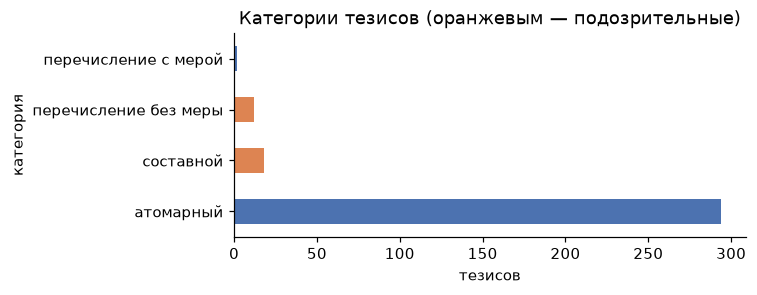

Подозрительных тезисов: 30 из 326 (9%); вопросов с ними: 25 из 71


,вопрос,№,тезис,категория
0,la-mcoll-005,3,"Назвал Ridge и объяснил, что $\lambda I$ делает матрицу обратимой",составной
1,mlv-diag-015,3,"Описал переобучение как разрыв между train и validation, предложил регуляризацию или больше данных",составной
2,mc-chain-005,4,"Предложил решения: ReLU, нормализация, residual-связи, клиппинг",перечисление без меры
3,np-debug-014,3,"Назвал типичные причины: транспонирование, забытый reshape, неверная ось агрегирования",перечисление без меры


In [3]:
WORD = r"[A-Za-zА-Яа-яЁё]+"
first_words = Counter(m.group(0).lower() for t in theses["тезис"] if (m := re.match(WORD, t)))
VERBS = {w for w in first_words if w not in {"правильно", "сначала", "первой"}}  # наречия, а не действия
QUANT = re.compile(r"\b(хотя бы|как минимум|минимум|все|оба|обе|один из|одну из|два|две|три|четыре)\b", re.I)
MANUAL_FALSE = {  # ручная проверка: правило их не различает
    ("mllin-coef-005", 2): "одно действие с оговоркой «не сказал…»",
    ("mlr-scale-011", 2): "«A, B или C» — достаточно одного варианта",
    ("stcup-risk-015", 2): "определение через двоеточие, а не перечисление",
}


def category(row):
    text = row["тезис"]
    if (row["вопрос"], row["№"]) in MANUAL_FALSE:
        return "атомарный"
    # действия, разделённые «или», — альтернативы, а не два обязательных шага
    if max(sum(w in VERBS for w in re.findall(WORD, p.lower())) for p in re.split(r"\s+или\s+", text)) >= 2:
        return "составной"
    segments = ([text.split(":", 1)[1]] if ":" in text else []) + re.findall(r"\(([^)]*)\)", text)
    if max((1 + len(re.findall(r",| и | или |/", s)) for s in segments), default=0) >= 3:
        return "перечисление с мерой" if QUANT.search(text) else "перечисление без меры"
    return "атомарный"


AMBIGUOUS = ["составной", "перечисление без меры"]
theses["категория"] = theses.apply(category, axis=1)
counts = theses["категория"].value_counts()
ax = counts.plot.barh(color=["#dd8452" if c in AMBIGUOUS else "#4c72b0" for c in counts.index], figsize=(6, 2.4))
ax.set_xlabel("тезисов")
ax.set_title("Категории тезисов (оранжевым — подозрительные)")
plt.show()

flag = theses["категория"].isin(AMBIGUOUS)
q_flag = theses.groupby("вопрос")["категория"].apply(lambda s: s.isin(AMBIGUOUS).any())
print(
    f"Подозрительных тезисов: {flag.sum()} из {len(theses)} ({flag.mean():.0%}); вопросов с ними: {q_flag.sum()} из {len(q_flag)}"
)
examples = [("la-mcoll-005", 3), ("mlv-diag-015", 3), ("mc-chain-005", 4), ("np-debug-014", 3)]
theses.set_index(["вопрос", "№"]).loc[examples].reset_index()

**Вывод.** Около 9% тезисов в трети вопросов подозрительны. Если «частично» для тезиса не определено, разметка
оценочного набора шумит, а модель наказывается за ответы, которые эксперт мог бы засчитать. Эвристика только отбирает
кандидатов — каждый отмеченный тезис разобран вручную вместе с эталоном (итог — в конце).

## 2. Почти-дубликаты

Если похожие вопросы попадут и в часть для подбора промптов, и в отложенную часть, качество на отложенной части будет
завышено. Сравниваем вопросы вместе с чек-листами по символьным n-граммам (устойчиво к словоформам).

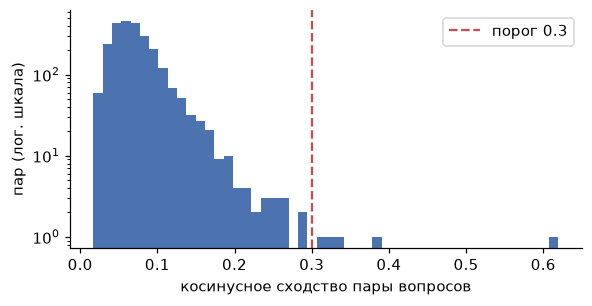

квантили сходства 50/90/99%: [0.067 0.113 0.2  ]


,вопрос A,вопрос B,сходство
0,mlm-loss-013,mc-surr-009,0.62
1,mlv-leak-007,mlv-leak-011,0.38
2,mc-chain-005,mc-vanish-013,0.33
3,mlv-leak-011,mlint-leak-011,0.32
4,mll-choose-007,mll-imb-015,0.32


In [4]:
def similarity(qs):
    tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
    return cosine_similarity(tfidf.fit_transform([q.question + " " + " ".join(q.rubric) for q in qs]))


S = similarity(open_qs)
iu = np.triu_indices(len(open_qs), 1)
THRESHOLD = 0.3
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(S[iu], bins=50, color="#4c72b0")
ax.axvline(THRESHOLD, color="#c44e52", ls="--", label=f"порог {THRESHOLD}")
ax.set_yscale("log")
ax.set_xlabel("косинусное сходство пары вопросов")
ax.set_ylabel("пар (лог. шкала)")
ax.legend()
plt.show()
print("квантили сходства 50/90/99%:", np.quantile(S[iu], [0.5, 0.9, 0.99]).round(3))

pairs = sorted(
    ((open_qs[a].id, open_qs[b].id, S[a, b]) for a, b in zip(*iu, strict=True) if S[a, b] >= THRESHOLD),
    key=lambda x: -x[2],
)
pd.DataFrame(pairs, columns=["вопрос A", "вопрос B", "сходство"]).round(2)

**Вывод.** Типичное сходство низкое (медиана около 0,07), пары выше 0,3 лежат далеко за 99-м перцентилем. Пара
`mlm-loss-013` / `mc-surr-009` (0,62) — по сути один вопрос: эталоны почти дословно совпадают, три тезиса из четырёх
общие. Остальные — вопросы об одном явлении: утечка данных, затухание градиентов, выбор функции потерь.

**Решение.** Оценочный набор делить по группам связанных вопросов: группа целиком попадает либо в часть для подбора,
либо в отложенную. Дубль объединить.

## Итог

Банк исправлен по результатам разделов 1–2. Те же проверки на текущем банке:

In [5]:
def summary(bank):
    qs = [q for q in bank.values() if q.type == "open"]
    th = pd.DataFrame([(q.id, i, t) for q in qs for i, t in enumerate(q.rubric, 1)], columns=["вопрос", "№", "тезис"])
    cats = th.apply(category, axis=1).value_counts()
    sim = similarity(qs)
    np.fill_diagonal(sim, 0)
    return {
        "вопросов с чек-листом": len(qs),
        "тезисов": len(th),
        "тезисов-словарей": int(th["тезис"].str.strip().str.fullmatch(r"\{'.*'\}").sum()),
        "перечислений без меры": int(cats.get("перечисление без меры", 0)),
        "составных": int(cats.get("составной", 0)),
        "макс. сходство пары вопросов": round(float(sim.max()), 2),
    }


pd.DataFrame({"до": summary(bank), "после": summary(load_bank())}).map(lambda v: f"{v:g}")

,до,после
вопросов с чек-листом,71,70
тезисов,326,326
тезисов-словарей,2,0
перечислений без меры,12,0
составных,18,13
макс. сходство пары вопросов,0.62,0.37


**Ручной разбор отмеченных тезисов** (вместе с эталонами):

| Группа | Тезисов | Что сделано |
|---|---|---|
| Перечисление без меры | 12 + 1 составной со списком | мера «хотя бы N из» и все варианты из эталона; меньше N, но не ноль — «частично» |
| Составной из независимых мыслей («как распознать» и «как лечить») | 4 | разбит на два тезиса |
| Требует расчёта, для которого в вопросе нет данных | 1 | переписан без расчёта |
| «Назвал X и объяснил почему», «применил метод и получил число» | 12 | оставлен: «объяснил» без «назвал» не бывает, разбиение создаст невыполнимый тезис |

Кроме того: исправлены 2 тезиса-словаря, валидатор теперь отклоняет такие пункты, дубль `mc-surr-009` удалён (его
уникальный тезис перенесён в `mlm-loss-013`), правило «одна мысль; для перечислений — мера» добавлено в промпт
генерации вопросов.

**Решения для следующих этапов.**

1. **Правило разметки** составных тезисов: названы все части — «раскрыт»; часть — «частично»; ничего — «не раскрыт».
   Суть без термина засчитывается, термин без сути — «частично». В карточке сценария для «частично» указывается, какая
   часть пропущена, — так метка известна по построению.
2. **Проверка правила на данных:** на пробных сценарных ответах сравнить долю верных вердиктов на составных и простых
   тезисах. Если на составных заметно хуже — разбивать и их.
3. **Промпт проверяющей модели** на этапе данных не меняется: сейчас для «упомянул, но не раскрыл» в нём допустимы оба
   вердикта. Версия с правилом из п. 1 — эксперимент этапа 2, сравнивается с текущей на оценочном наборе.
4. **Разбиение набора** — по группам связанных вопросов из раздела 2.